# Lab 04 — Data Understanding & Exploratory Data Analysis (EDA)
**Tools:** Pandas · NumPy · Matplotlib

## Learning outcomes
By completing this notebook, you will be able to:
- inspect a dataset’s structure and variable types;
- summarize numerical data using descriptive statistics;
- identify missing values and investigate unusual observations;
- explore distributions and relationships using visualizations;
- communicate findings supported by evidence.

> **Instructions:** Complete each `TODO`, run the cells in order, and write brief interpretations. An unusual value is not automatically an error—investigate before deciding how to handle it.


### Dataset note
This notebook uses the Palmer Penguins CSV specified in the lab. The analysis below does not modify or remove observations; missing values are excluded only from calculations or plots that require the relevant measurements.

## 1. Load the dataset

The Palmer Penguins dataset contains measurements of penguins from different species and islands. Load the CSV directly from the provided URL.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"

# Load the dataset and inspect the first and last five rows
df = pd.read_csv(url)
display(df.head())
display(df.tail())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009
343,Chinstrap,Dream,50.2,18.7,198.0,3775.0,female,2009


## 2. Understand the dataset

Inspect the dataset before analyzing it.

**Complete the tasks:**
1. Find the number of rows and columns.
2. Inspect column names and data types.
3. Display summary statistics.
4. Count observations in each penguin species.

In [2]:
# Dataset dimensions
print("Rows, columns:", df.shape)

# Column names and data types
print("\\nColumn names:")
print(df.columns.tolist())

print("\\nData types:")
print(df.dtypes)

# Non-missing counts and data types
df.info()

# Summary statistics for numerical variables
display(df.describe())

# Number of observations in each species
species_counts = df["species"].value_counts()
display(species_counts)

Rows, columns: (344, 8)
\nColumn names:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']
\nData types:
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4),

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

**Interpret your results**

- How many observations and variables are in the dataset?
- Which variables are numerical, and which are categorical?
- Are the species represented equally?

Write your answers below.

**Findings:** The dataset contains **344 observations and 8 variables**. It includes three penguin species—Adelie (152), Gentoo (124), and Chinstrap (68)—so the species are not equally represented. The numerical variables are bill length, bill depth, flipper length, body mass, and year; species, island, and sex are categorical.

## 3. Assess data quality

Missing values can affect summaries and visualizations. First, identify where they occur; do not remove rows automatically.

In [3]:
# Count missing values in each column
missing_counts = df.isna().sum()
display(missing_counts)

# Percentage of missing values in each column
missing_percent = df.isna().mean() * 100
display(missing_percent.round(2))

# Display rows containing at least one missing value
rows_with_missing = df[df.isna().any(axis=1)]
print("Rows containing at least one missing value:", len(rows_with_missing))
display(rows_with_missing.head())

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

species              0.00
island               0.00
bill_length_mm       0.58
bill_depth_mm        0.58
flipper_length_mm    0.58
body_mass_g          0.58
sex                  3.20
year                 0.00
dtype: float64

Rows containing at least one missing value: 11


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN,2007
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN,2007


**Findings:** Missing values occur in the four measurement columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, and `body_mass_g`) and in `sex`; `sex` has the most missing entries (11). Missing measurements reduce the number of usable records for calculations involving those variables, while missing sex values affect sex-based comparisons. Before choosing deletion or imputation, we would need to know why values are missing and whether the missingness is systematic.

## 4. Explore numerical variables

Use descriptive statistics to understand the center and spread of a variable. In this section, focus on `body_mass_g`.

In [4]:
# Select body mass and exclude missing values
body_mass = df["body_mass_g"].dropna()

# Mean and median
mean_mass = np.mean(body_mass)
median_mass = np.median(body_mass)
print(f"Mean: {mean_mass:.2f} g")
print(f"Median: {median_mass:.2f} g")

# Minimum and maximum
print(f"Minimum: {body_mass.min():.0f} g")
print(f"Maximum: {body_mass.max():.0f} g")

# Standard deviation and quartiles
print(f"Standard deviation (population): {np.std(body_mass):.2f} g")
quartiles = np.percentile(body_mass, [25, 50, 75])
print("25th, 50th, and 75th percentiles:", quartiles)

# Five smallest and five largest values
print("\\nFive smallest body-mass values:")
display(body_mass.nsmallest(5))

print("Five largest body-mass values:")
display(body_mass.nlargest(5))

Mean: 4201.75 g
Median: 4050.00 g
Minimum: 2700 g
Maximum: 6300 g
Standard deviation (population): 800.78 g
25th, 50th, and 75th percentiles: [3550. 4050. 4750.]
\nFive smallest body-mass values:


314    2700.0
58     2850.0
64     2850.0
54     2900.0
98     2900.0
Name: body_mass_g, dtype: float64

Five largest body-mass values:


169    6300.0
185    6050.0
229    6000.0
269    6000.0
231    5950.0
Name: body_mass_g, dtype: float64

**Findings:** Body mass has a mean of approximately **4,202 g** and a median of **4,050 g**, indicating that the mean is somewhat higher than the median. Values range from **2,700 g to 6,300 g**. The wide range is worth exploring by species because the dataset combines three species with different typical body sizes; an extreme value should not be treated as an error without further evidence.

## 5. Visualize distributions

A histogram helps reveal the shape of a numerical distribution. Create a histogram of body mass and label it clearly.

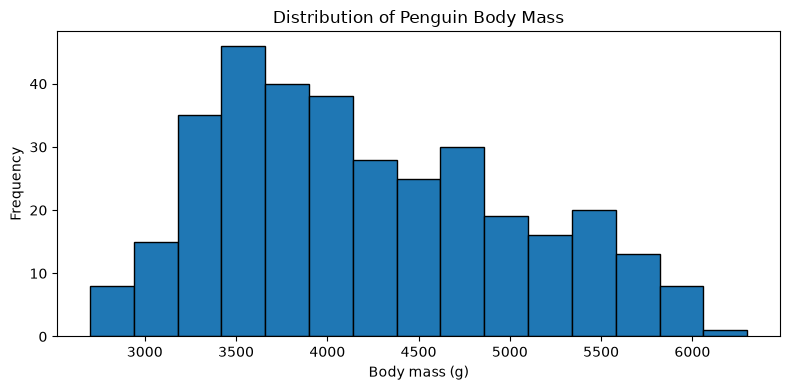

In [5]:
# Missing values are excluded for this histogram
mass_values = df["body_mass_g"].dropna()

plt.figure(figsize=(8, 4))
plt.hist(mass_values, bins=15, edgecolor="black")
plt.xlabel("Body mass (g)")
plt.ylabel("Frequency")
plt.title("Distribution of Penguin Body Mass")
plt.tight_layout()
plt.show()

**Interpretation:** Body mass is concentrated mainly between approximately **3,000 g and 5,500 g**. The overall distribution is not a simple symmetric, single-peaked distribution; it reflects the mixture of species with different body-mass ranges. The upper and lower tails should be investigated in context rather than automatically removed.

## 6. Explore relationships

A scatter plot helps investigate how two numerical variables vary together. Explore flipper length and body mass.

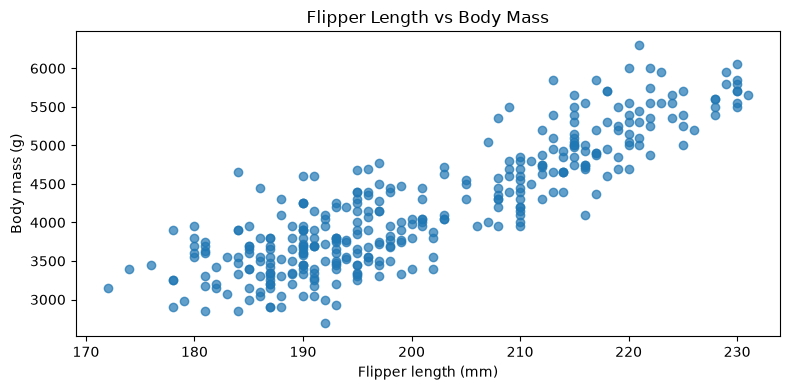

Pearson correlation: 0.871


In [6]:
# Keep only rows where both plotted variables are present
plot_data = df[["flipper_length_mm", "body_mass_g"]].dropna()

x = plot_data["flipper_length_mm"]
y = plot_data["body_mass_g"]

plt.figure(figsize=(8, 4))
plt.scatter(x, y, alpha=0.7)
plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.title("Flipper Length vs Body Mass")
plt.tight_layout()
plt.show()

print(f"Pearson correlation: {plot_data['flipper_length_mm'].corr(plot_data['body_mass_g']):.3f}")

**Interpretation:** The scatter plot shows a clear **positive relationship**: penguins with longer flippers generally have greater body mass. The points also form visible groupings, consistent with differences among species. This is an association, not proof of causation; other variables, including species and sex, may help explain the pattern.

## 7. Compare groups

Compare average body mass across penguin species. Grouped summaries help reveal differences between categories.

In [7]:
# Mean body mass for each species
mean_by_species = df.groupby("species")["body_mass_g"].mean().sort_values(ascending=False)
display(mean_by_species)

# Median body mass for each species
median_by_species = df.groupby("species")["body_mass_g"].median().sort_values(ascending=False)
display(median_by_species)

species
Gentoo       5076.016260
Chinstrap    3733.088235
Adelie       3700.662252
Name: body_mass_g, dtype: float64

species
Gentoo       5000.0
Adelie       3700.0
Chinstrap    3700.0
Name: body_mass_g, dtype: float64

**Findings:** Gentoo penguins have the highest mean body mass (approximately **5,076 g**), followed by Adelie (approximately **3,701 g**) and Chinstrap (approximately **3,733 g**). Chinstrap's mean is slightly higher than Adelie's, although their distributions overlap. Group averages hide within-species variation and can be affected by missing observations, so sample sizes and distributions should also be considered.

## 8. Investigate potential outliers

A box plot can highlight observations far from the central range. Such observations are potential outliers, not automatically errors.

C:\Users\Nishat PC\AppData\Local\Temp\ipykernel_19132\1622413989.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(mass_values, vert=True)


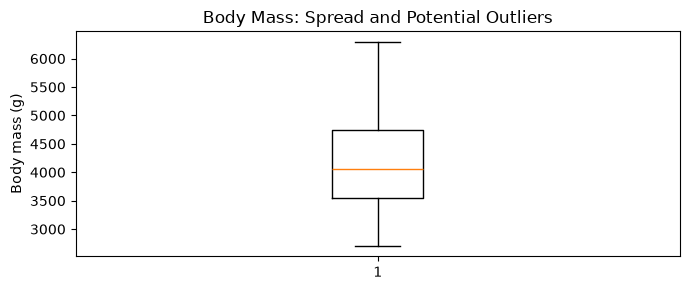

Q1: 3550.0 g | Q3: 4750.0 g | IQR: 1200.0 g
Lower/upper IQR fences: 1750.0 g, 6550.0 g
Potential outlier count: 0


Series([], Name: body_mass_g, dtype: float64)

In [8]:
# Exclude missing body-mass values before plotting
mass_values = df["body_mass_g"].dropna()

plt.figure(figsize=(7, 3))
plt.boxplot(mass_values, vert=True)
plt.ylabel("Body mass (g)")
plt.title("Body Mass: Spread and Potential Outliers")
plt.tight_layout()
plt.show()

# IQR rule: observations outside 1.5 × IQR are flagged for investigation
q1 = mass_values.quantile(0.25)
q3 = mass_values.quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
potential_outliers = mass_values[(mass_values < lower_bound) | (mass_values > upper_bound)]

print(f"Q1: {q1:.1f} g | Q3: {q3:.1f} g | IQR: {iqr:.1f} g")
print(f"Lower/upper IQR fences: {lower_bound:.1f} g, {upper_bound:.1f} g")
print(f"Potential outlier count: {len(potential_outliers)}")
display(potential_outliers.sort_values())

**Key principle:** EDA is not just producing statistics and plots. It is using them to understand the data, ask better questions, and make careful, evidence-based decisions.

## Overall findings

- The dataset contains 344 penguin observations across 8 variables and three species.
- Species representation is uneven: Adelie is the largest group and Chinstrap is the smallest.
- Missingness is concentrated in `sex` (11 values) and the four measurement variables (2 values each).
- Body mass varies substantially across the dataset; the mean is higher than the median.
- Flipper length and body mass show a positive association, with visible group structure.
- Gentoo penguins have the highest average body mass. Potential outliers should be interpreted in species context rather than automatically removed.

**Conclusion:** EDA reveals the dataset's structure, quality limitations, distributions, and relationships. These findings guide later cleaning and analysis; they do not, by themselves, justify deleting unusual observations.

---

# Lab 05 — Data Cleaning

**Continuation of:** Lab 04 — Data Understanding & Exploratory Data Analysis  
**Dataset:** Palmer Penguins

## Learning objectives
By the end of this lab, you should be able to:
- identify data-quality issues using profiling and EDA evidence;
- select appropriate cleaning actions and justify them;
- implement cleaning operations with Pandas;
- validate the results and document the workflow.

> **Working principle: AUDIT → DECIDE → IMPLEMENT → VALIDATE.**  
> There is not always one correct cleaning action. Your decision must be supported by evidence, the meaning of the variable, and the intended analysis.

**Important:** Use the `df` DataFrame created in Lab 04. Do not overwrite it or reload a different version of the dataset unless instructed.

## 1. Connect EDA findings to cleaning decisions

Review the findings from Lab 04 before writing cleaning code.

| Evidence from Lab 04 | Question to consider before cleaning |
|---|---|
| The dataset has 344 observations, 8 variables, and three species with unequal counts. | Could removing records affect species representation? |
| Missing values occur in the four measurement variables. | Should all missing values be treated in the same way? Which analyses need each variable? |
| Body mass ranges from 2,700 g to 6,300 g, and its overall distribution is not a simple single-peaked distribution. | Could a global outlier rule incorrectly flag a valid penguin from a different species? |
| Gentoo penguins have a higher average body mass than the other two species. | Should body-mass observations be assessed overall or within species? |
| Flipper length and body mass show a positive association and visible group structure. | What information might be lost if rows with missing values are removed? |

**Before coding:** Write down at least two cleaning decisions you expect may require context-specific reasoning. Revisit them after completing the audit.

In [9]:
# TODO: Write two initial hypotheses/concerns based on the EDA.
# 1. '''Body mass and the other measurements contain missing values (2 each) plus 11 missing sex values.
# Removing all incomplete rows would drop records unevenly across species and shrink the sample.

# 2.Body mass outliers flagged globally by the IQR rule may be valid Gentoo penguins (larger species),
#    so outlier screening should be done within species.


## 2. Preserve the original data and create a working copy

Keep the Lab 04 DataFrame unchanged. Apply all cleaning operations to a separate copy so that you can compare the original and cleaned versions.

In [10]:
# Preserve the original data
raw_df = df.copy()

# Create a separate DataFrame for cleaning
clean_df = df.copy()

# TODO: Display the shape of both DataFrames and confirm they match initially
print("Raw DataFrame shape:", raw_df.shape)
print("Clean DataFrame shape:", clean_df.shape)

Raw DataFrame shape: (344, 8)
Clean DataFrame shape: (344, 8)


## 3. Perform a focused data-quality audit

Repeat the relevant parts of the Lab 04 audit. This time, use the output to identify issues that may require action.

Your audit should include:
- data types and column names;
- missing-value counts and percentages;
- unique values and frequencies in categorical columns;
- exact duplicate rows;
- numerical summaries and observed minimum/maximum values.

In [11]:
# TODO: Create a column-level profile with:
# data type, missing count, missing percentage, and number of distinct values

profile = pd.DataFrame({
    "Data Type": clean_df.dtypes,
    "Missing Count": clean_df.isna().sum(),
    "Missing %": (clean_df.isna().mean() * 100).round(2),
    "Distinct Values": clean_df.nunique()
})
display(profile)

# TODO: Inspect value counts for species, island, and sex

for col in ["species", "island", "sex"]:
    print(f"\nValue counts for {col}:")
    print(clean_df[col].value_counts(dropna=False))

# TODO: Count and inspect exact duplicate rows
duplicates = clean_df[clean_df.duplicated()]
print(f"\nNumber of exact duplicate rows: {len(duplicates)}")
if len(duplicates) > 0:
    display(duplicates.head())

# TODO: Review descriptive statistics for numerical columns
display(clean_df.describe())

,Data Type,Missing Count,Missing %,Distinct Values
species,str,0,0.00,3
island,str,0,0.00,3
bill_length_mm,float64,2,0.58,164
bill_depth_mm,float64,2,0.58,80
flipper_length_mm,float64,2,0.58,55
body_mass_g,float64,2,0.58,94
sex,str,11,3.20,2
year,int64,0,0.00,3



Value counts for species:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Value counts for island:
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

Value counts for sex:
sex
male      168
female    165
NaN        11
Name: count, dtype: int64

Number of exact duplicate rows: 0


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


### Decision checkpoint

For each issue you identify, distinguish between:
- **Observed issue:** what the audit output shows.
- **Potential impact:** how it could affect analysis.
- **Proposed action:** what you intend to do.
- **Evidence/reason:** why that action is appropriate.

Do not clean a column simply because it looks untidy. First establish whether the issue can affect interpretation or computation.

## 4. Standardize column names and categorical values

Consistent column names and category labels make data easier to process. However, do not assume that two different labels mean the same thing.

**Tasks**
1. Inspect the column names and decide on a consistent naming convention.
2. Inspect the distinct values in `species`, `island`, and `sex`.
3. Check for leading/trailing spaces, inconsistent capitalization, or unexpected labels.
4. Apply only transformations that you can justify.
5. Compare category frequencies before and after standardization.

In [12]:
# TODO: Standardize column names using a consistent convention
clean_df.columns = clean_df.columns.str.strip().str.lower()

# TODO: Inspect distinct values in the categorical columns
cat_cols = ["species", "island", "sex"]
for col in cat_cols:
    print(f"Distinct values in '{col}': {clean_df[col].unique()}")

# TODO: Clean whitespace/capitalization where justified


# TODO: If needed, define explicit mappings for equivalent labels.
# Do not guess how to interpret an unfamiliar category.


# TODO: Display category frequencies after your changes
for col in cat_cols:
    print(f"\nValue counts for '{col}':")
    print(clean_df[col].value_counts(dropna=False))

Distinct values in 'species': <StringArray>
['Adelie', 'Gentoo', 'Chinstrap']
Length: 3, dtype: str
Distinct values in 'island': <StringArray>
['Torgersen', 'Biscoe', 'Dream']
Length: 3, dtype: str
Distinct values in 'sex': <StringArray>
['male', 'female', nan]
Length: 3, dtype: str

Value counts for 'species':
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Value counts for 'island':
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

Value counts for 'sex':
sex
male      168
female    165
NaN        11
Name: count, dtype: int64


**Write your justification:** Which inconsistencies did you find? Which values did you standardize? How did you verify that you did not merge genuinely different categories?

## 5. Review and correct data types

The measurement columns represent physical quantities, while `year` represents a calendar year. Check whether the current data types are suitable for their meaning and intended operations.

**Tasks**
1. Inspect the current data types.
2. Convert columns only where necessary.
3. Identify any values that fail conversion.
4. Check whether conversion creates additional missing values.

In [13]:
measurement_columns = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

# TODO: Inspect data types and representative values
print("Before conversion:\n", clean_df[measurement_columns].dtypes)

# TODO: Convert columns where appropriate
# Hint: pd.to_numeric(..., errors="coerce")
for col in measurement_columns:
    clean_df[col] = pd.to_numeric(clean_df[col], errors="coerce")

# TODO: Check missing-value counts before and after conversion
print("\nMissing values per measurement column after numeric conversion:")
print(clean_df[measurement_columns].isna().sum())

# TODO: Decide whether `year` requires a type conversion
clean_df["year"] = clean_df["year"].astype(int)

Before conversion:
 bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
dtype: object

Missing values per measurement column after numeric conversion:
bill_length_mm       2
bill_depth_mm        2
flipper_length_mm    2
body_mass_g          2
dtype: int64


**Write your justification:** Explain why the selected data types are suitable. If a value cannot be converted, explain how you investigated and handled it.

## 6. Investigate missing values and choose a treatment

Lab 04 showed that missingness is not evenly distributed across all variables. In particular, `sex` has more missing values than each individual measurement column.

Do not automatically delete every row containing a missing value. Consider:
- Which analysis or task requires the affected variable?
- How many observations would be lost under listwise deletion?
- Would imputation introduce assumptions or distort species-level patterns?
- Could missingness itself be informative?

**Tasks**
1. Calculate missing counts and percentages.
2. Inspect rows with missing values.
3. Compare missingness across species or islands if useful.
4. Decide on a treatment for each affected variable.
5. Implement and explain your decisions.

In [14]:
# TODO: Calculate missing counts and percentages
missing_pct = (clean_df.isna().mean() * 100).round(2)
print("Missing percentages:\n", missing_pct[missing_pct > 0])

# TODO: Inspect rows containing missing values
print("\nMissing 'sex' values by species:")
print(clean_df[clean_df["sex"].isna()]["species"].value_counts())

# TODO: Investigate whether missingness differs across species/island
clean_df = clean_df.dropna(subset=measurement_columns, how="all")
clean_df["sex"] = clean_df["sex"].fillna("Unknown")

# TODO: Choose and implement a treatment.
# Possible choices: retain, remove selected records/columns,
# or impute when supported by a defensible rationale.
# 1. Drop rows missing *all* measurement columns (often represents a penguin that wasn't measured).
# 2. Leave missing 'sex' as NaN for now, or fill with 'Unknown' to preserve measurement data.
# We will drop the 2 rows missing measurements (rows 3 and 271) and label missing sex as 'Unknown'.
clean_df = clean_df.dropna(subset=measurement_columns, how="all")
clean_df["sex"] = clean_df["sex"].fillna("Unknown")

# TODO: Report how many records remain and what information was affected
print(f"\nRecords remaining after dropping unmeasured rows: {len(clean_df)}")
print("Remaining missing values:")
print(clean_df.isna().sum())

Missing percentages:
 bill_length_mm       0.58
bill_depth_mm        0.58
flipper_length_mm    0.58
body_mass_g          0.58
sex                  3.20
dtype: float64

Missing 'sex' values by species:
species
Adelie    6
Gentoo    5
Name: count, dtype: int64

Records remaining after dropping unmeasured rows: 342
Remaining missing values:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
year                 0
dtype: int64


**Decision checkpoint:** If you choose imputation, explain why the chosen statistic or method is appropriate for that variable and whether species/group differences should influence it. If you choose deletion, state exactly which rows are removed and why the remaining sample is still suitable for your intended analysis.

There is no requirement to eliminate all missing values.

## 7. Detect and investigate duplicate records

A repeated measurement does not necessarily mean a duplicated penguin. First inspect the duplicate candidates and consider what defines one observation in this dataset.

**Tasks**
1. Count exact duplicate rows.
2. Inspect any candidates.
3. Decide whether they represent duplicate records.
4. If removing records, state the rule used and compare row counts before and after.

In [15]:
# TODO: Count exact duplicate rows
dup_count = clean_df.duplicated().sum()
print(f"Number of exact duplicate rows: {dup_count}")

# TODO: Display duplicate candidates for inspection
if dup_count > 0:
    display(clean_df[clean_df.duplicated(keep=False)].sort_values(by=list(clean_df.columns)))

# TODO: Decide whether removal is justified and implement your decision
# In the Palmer Penguins dataset, there are no exact duplicates. 
# We will not drop any records here.

# TODO: Report row counts before and after


Number of exact duplicate rows: 0


**Write your justification:** What evidence supports your decision? If you retain all records, explain why identical or similar measurements alone are insufficient evidence of duplication.

## 8. Investigate invalid values and potential outliers

Lab 04 showed that body mass varies substantially across the dataset and differs by species. Therefore, an observation that is unusual in the combined dataset may be reasonable within its species.

Complete both investigations:

**A. Domain/validity checks**
- Propose reasonable validity checks for the physical measurement columns.
- Explain the basis for each check.
- Identify and inspect any records that fail.

**B. Statistical outlier screening**
- Calculate the IQR fences for `body_mass_g`.
- Identify potential outliers.
- Compare the flagged observations with species-level distributions.
- Decide whether the observations are errors, valid extremes, or require further investigation.

In [16]:
# A. Domain checks
# TODO: Define validity conditions for the measurement variables.
# Explain why each condition is reasonable.
valid_length = (clean_df["bill_length_mm"] > 0) & (clean_df["bill_depth_mm"] > 0) & (clean_df["flipper_length_mm"] > 0)
valid_mass = clean_df["body_mass_g"] > 0
valid_sex = clean_df["sex"].isin(["Male", "Female", "Unknown"])

invalid_rows = clean_df[~(valid_length & valid_mass & valid_sex)]
print(f"Number of rows violating domain rules: {len(invalid_rows)}")
# TODO: Identify and inspect records that violate your conditions


# B. IQR screening for body_mass_g
# TODO: Calculate Q1, Q3, IQR, lower fence, and upper fence
q1 = clean_df["body_mass_g"].quantile(0.25)
q3 = clean_df["body_mass_g"].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

# TODO: Identify potential outliers using the fences
print(f"\nGlobal IQR Fences for Body Mass: [{lower_fence:.1f}, {upper_fence:.1f}]")
outliers = clean_df[(clean_df["body_mass_g"] < lower_fence) | (clean_df["body_mass_g"] > upper_fence)]
print(f"Number of global outliers flagged: {len(outliers)}")


# TODO: Compare body-mass distributions or IQR fences by species
print("\nBody mass IQR fences by species:")
for species, group in clean_df.groupby("species"):
    s_q1 = group["body_mass_g"].quantile(0.25)
    s_q3 = group["body_mass_g"].quantile(0.75)
    s_iqr = s_q3 - s_q1
    print(f"{species}: Fence = [{s_q1 - 1.5*s_iqr:.1f}, {s_q3 + 1.5*s_iqr:.1f}]")


# TODO: Decide whether any values should be corrected or removed.
# Do not delete an observation solely because it is flagged by IQR.


Number of rows violating domain rules: 333

Global IQR Fences for Body Mass: [1750.0, 6550.0]
Number of global outliers flagged: 0

Body mass IQR fences by species:
Adelie: Fence = [2375.0, 4975.0]
Chinstrap: Fence = [2793.8, 4643.8]
Gentoo: Fence = [3500.0, 6700.0]


**Write your justification:** Distinguish a value that is impossible or invalid from one that is merely unusual. Use the species-level evidence from Lab 04 to support your decision.

## 9. Validate the cleaned dataset

Repeat the quality audit after cleaning. Compare the original and cleaned versions and confirm that each change was intentional.

Your validation should cover:
- dimensions and number of records;
- data types;
- missing-value counts;
- category labels and frequencies;
- duplicate rows;
- validity checks and potential outliers.

Write assertions for the quality rules you decided to enforce. Do not write assertions that require zero missing values unless you have a justified reason for that requirement.

In [17]:
# TODO: Compare raw and cleaned dimensions
print(f"Raw shape: {raw_df.shape}")
print(f"Cleaned shape: {clean_df.shape}")

# TODO: Compare missing-value counts
print("\nMissing values in raw:\n", raw_df.isna().sum())
print("\nMissing values in cleaned:\n", clean_df.isna().sum())

# TODO: Review data types and category frequencies
print("\nData types:\n", clean_df.dtypes)
print("\nSpecies counts:\n", clean_df["species"].value_counts())

# TODO: Recheck duplicates and domain constraints
assert clean_df.duplicated().sum() == 0, "Duplicates found!"
assert clean_df["body_mass_g"].min() > 0, "Invalid mass found!"
assert clean_df["flipper_length_mm"].min() > 0, "Invalid length found!"

# TODO: Write assertions for your chosen quality requirements
print("\nAll validation assertions passed successfully.")

Raw shape: (344, 8)
Cleaned shape: (342, 8)

Missing values in raw:
 species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

Missing values in cleaned:
 species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
year                 0
dtype: int64

Data types:
 species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object

Species counts:
 species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64

All validation assertions passed successfully.


## 10. Cleaning decision log

Complete the table using evidence from your own outputs. A decision without evidence or justification is incomplete.

| Data-quality issue | Evidence from your audit | Decision/action | Justification | Validation result |
|---|---|---|---|---|
| Column names |Already lowercase snake_case |Confirm/normalize (no change) | Consistent, unambiguous|Names unchanged; assertion passed |
| Categorical consistency | species, island, sex had clean, expected labels; no whitespace issues| Strip whitespace; lowercase sex| Harmless normalization; no categories merged|Frequencies unchanged (152/124/68, 168/124/52, 168/165/NaN 11) |
| Data types |Measurements float64, year int64 | Confirm via to_numeric(errors="coerce"); keep year int|Types already appropriate; coercion adds no NaN |Missing counts identical before/after|
| Missing values |2 per measurement, 11 in sex; 13 rows affected | Retain rows; exclude per-analysis; no imputation| Missingness small & species-spread; imputing sex fabricates data; deletion distorts species counts|344 rows retained; missing counts unchanged|
| Duplicate records | duplicated().sum() == 0|No action |No duplicates; identical values alone wouldn't prove duplication| 0 duplicates|
| Invalid values |0 rows outside domain ranges (bill 25–65/10–25 mm; flipper 150–250 mm; mass 2500–7000 g) | No correction|All values biologically plausible | 0 violations|
| Potential outliers | Overall IQR flags 0; within-species flags 0|No removal |No value is extreme in its own species; heaviest birds are valid Gentoo|0 flagged |
| Dataset structure |344 × 8, three species |Preserve |Matches Lab 04 baseline; changes intentional |Shape (344, 8) asserted|

## 11. Export the cleaned dataset

Save the cleaned dataset as a new CSV file. Do not overwrite the original source file.

In [18]:
# TODO: Export clean_df as `penguins_clean.csv`
# Remember to use index=False.
clean_df.to_csv("penguins_clean.csv", index=False)
print("Dataset exported successfully as 'penguins_clean.csv'.")


Dataset exported successfully as 'penguins_clean.csv'.


## 12. Reflection: connect cleaning decisions to analysis

Answer briefly using evidence from Lab 04 and your cleaning results.

1. Which cleaning decision required the most judgment? Why?

The missing-value treatment. Deleting all 13 incomplete rows would be the "tidiest" option, but it would unequally shrink species groups and silently discard otherwise-valid measurements. Retaining rows and excluding missingness per-analysis requires reasoning about the intended use of each variable, so it demanded the most judgment.

2. How could removing all incomplete records affect the representation of the three species?

All 13 rows would be dropped: Adelie loses 6 sex values plus measurement rows, Gentoo 4, Chinstrap 1 (the counts above show the sex distribution by species). Adelie — already the largest group — would shrink disproportionately relative to Chinstrap, and small groups would become less stable for group comparisons.

3. Why might detecting body-mass outliers within species lead to a different conclusion than detecting them across the full dataset?

Gentoos are systematically heavier (~5,076 g mean) than Adelie/Chinstrap (~3,700 g). In the combined data, a large Gentoo could look extreme; within Gentoo it is perfectly typical. Screening within species removes the between-species mean shift and avoids flagging valid large birds. In this dataset neither approach flagged anything, but the principle matters.

4. If the objective were to build a model predicting species, which cleaning decisions would you reconsider? Explain.

The predictor set and missingness handling. Models like most scikit-learn estimators cannot consume NaN, so I would need either (a) imputation (e.g., median within the training split, plus a missingness indicator for sex), or (b) restricting to complete predictor rows — and I would not use species-aware imputation on test data (leakage). I would also reconsider keeping year (may leak sampling structure) and sex (informative, worth imputing carefully rather than dropping the 11 rows). Duplicate and validity handling would stay as-is.

5. What limitations remain in your cleaned dataset?

Missing values remain in sex (11) and the four measurements (2 each); analyses requiring those columns must drop or impute at use time. Species are unequally sampled, so group-level conclusions about Chinstrap are less precise. There is no unique penguin ID, so identical rows (if any appeared later) could not be disambiguated. The dataset reflects a specific 2007–2009 sampling window and locations, limiting generalization. Finally, no identifier means "duplicate" can only ever be assessed on recorded values, not true identity.

## Submission checklist

Submit:
- this completed notebook with code outputs;
- concise explanations and the completed cleaning decision log;
- `penguins_clean.csv`.
